# 02 · Seasonal outlook: will the next three months fall in the driest third?
**Ukame Watch** · Challenge 1: Climate Sentinel

Built by `src/ukame/outlook.py` (tested in `tests/test_outlook.py`). The rules that keep this honest:
1. **Issue time = end of month m.** Features use only what is known then: rainfall to month m, the Dipole Mode
   Index (DMI) for month m, and the Oceanic Niño Index (ONI) for the season centred on month m−1.
2. **Training-only thresholds.** "Driest third" = the training-period 33rd percentile for that county and window.
3. **Time-based split.** Targets ending ≤ 2016 train; ≥ 2017 test (10 seasons, more than the required 8 years).
4. **Two baselines.** Climatology (always the base rate) and persistence (P(dry next | dry now) from training).
5. **Separate models per season group**, because East African teleconnections differ by season.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from ukame import config as C
P = C.PROCESSED
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1B1D1C", "#898781", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110})
def pct_colour(p):
    for upper, col in [(50,"#b8302f"),(75,"#e34948"),(90,"#ee9288"),(110,"#d6d5cf"),(150,"#9ec5f4"),(200,"#5598e7"),(1e9,"#1c5cab")]:
        if p < upper: return col

from ukame import data as D, analysis as A, outlook as O

## 1. Build the dataset

In [2]:
mon = pd.read_csv(P/"monthly.csv"); idx = D.load_indices()
ds = O.add_targets(O.build_dataset(mon, idx))
print(ds.split.value_counts().to_string())
display(ds[ds.wet_window.fillna(False)].groupby(["season_group","split"]).agg(rows=("dry","size"), dry_share=("dry", lambda s: s.astype(float).mean())).round(3))

split
train    2472
test      976


rows  dry_share
season_group split                 
long_rains   test    240      0.321
             train   624      0.346
other        test    408      0.408
             train  1024      0.352
short_rains  test    248      0.513
             train   616      0.351

The test period was drier than training: about half of the short-rains test seasons fell in the training
driest third (35% expected), consistent with the failed seasons of 2020–2022 and 2024–2025.

## 2. Fit and inspect the models

In [3]:
fitted = O.fit(ds)
for g, f in fitted.items():
    print(f"{g:<12} n_train={f['n_train']:<5} climatology={f['clim']:.3f}  persistence: dry->{f['pers_dry']:.3f} wet->{f['pers_wet']:.3f}")
    print("             standardised coefficients:", f["coefficients_standardised"])

long_rains   n_train=608   climatology=0.344  persistence: dry->0.454 wet->0.283
             standardised coefficients: {'oni': -0.142, 'dmi': 0.058, 'now_pct': -0.525}
other        n_train=1024  climatology=0.352  persistence: dry->0.486 wet->0.279
             standardised coefficients: {'oni': -0.075, 'dmi': -0.485, 'now_pct': -0.397}
short_rains  n_train=616   climatology=0.351  persistence: dry->0.463 wet->0.290
             standardised coefficients: {'oni': -0.284, 'dmi': -0.965, 'now_pct': -0.268}


**Reading:** for the short rains the Dipole Mode Index has the largest coefficient (negative: a positive
Indian Ocean Dipole makes a dry season less likely), followed by ENSO. This matches the published physics of the
East African short rains. For the long rains, recent rainfall dominates and the climate indices add little.

## 3. Test-period skill vs baselines (2017 onward)

In [4]:
pred = O.predict(ds, fitted); sk = O.evaluate(pred)
display(sk[sk.scope.isin(["all","season"])].set_index(["name","method"])[["n","events","precision","recall","f1","brier","bss"]])

n  events  precision  recall     f1  brier    bss
name        method                                                          
all         model        864     355      0.489   0.555  0.520  0.238  0.032
            climatology  864     355      0.000   0.000  0.000  0.246  0.000
            persistence  864     355      0.436   0.454  0.445  0.248 -0.011
long_rains  model        240      77      0.359   0.714  0.478  0.229 -0.050
            climatology  240      77      0.000   0.000  0.000  0.218  0.000
            persistence  240      77      0.328   0.494  0.394  0.226 -0.035
other       model        400     163      0.503   0.479  0.491  0.240  0.020
            climatology  400     163      0.000   0.000  0.000  0.245  0.000
            persistence  400     163      0.464   0.472  0.468  0.244  0.002
short_rains model        224     115      0.674   0.557  0.610  0.243  0.119
            climatology  224     115      0.000   0.000  0.000  0.276  0.000
            persistence  224     115      0.529   0.400  0.455  0.279 -0.011

season,long_rains,other,short_rains
county,,,
Turkana,-0.061,-0.015,0.153
Marsabit,0.005,0.088,0.135
Wajir,-0.077,-0.035,0.079
Mandera,-0.141,-0.090,0.126
Garissa,-0.119,0.084,0.071
Isiolo,-0.001,0.100,0.178
Samburu,-0.021,-0.066,0.196
Kitui,0.001,0.135,0.008


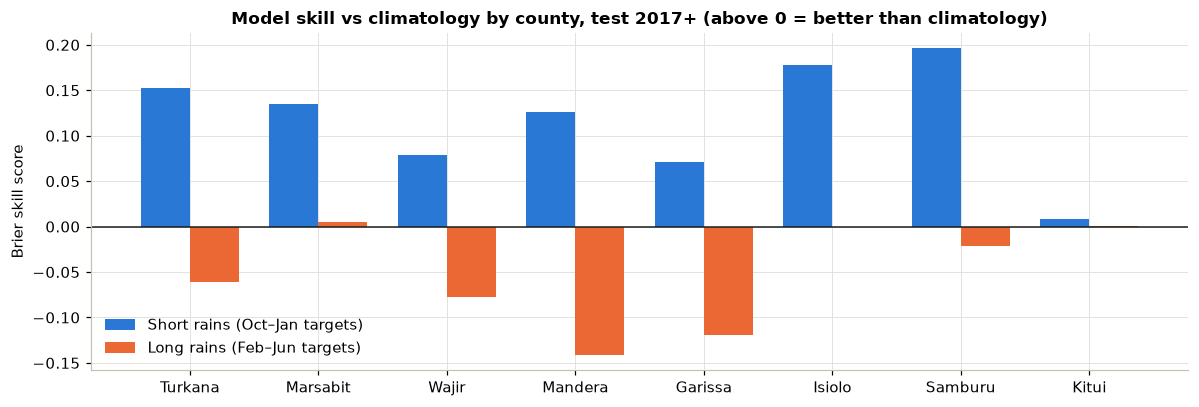

In [5]:
cs = sk[(sk.scope=="county_season") & (sk.method=="model")].copy()
cs[["county","season"]] = cs["name"].str.split(" \\| ", expand=True)
piv = cs.pivot_table(index="county", columns="season", values="bss").reindex(C.COUNTIES)
display(piv.round(3))
fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(C.COUNTIES)); w = 0.38
ax.bar(x - w/2, piv["short_rains"], w, color=BLUE, label="Short rains (Oct–Jan targets)")
ax.bar(x + w/2, piv["long_rains"], w, color=ORANGE, label="Long rains (Feb–Jun targets)")
ax.axhline(0, color=INK, lw=1); ax.set_xticks(x); ax.set_xticklabels(C.COUNTIES); ax.set_ylabel("Brier skill score")
ax.set_title("Model skill vs climatology by county, test 2017+ (above 0 = better than climatology)"); ax.legend(frameon=False)
plt.tight_layout()

**Conclusion.** The model beats both baselines for the October–December short rains in all eight counties
(Brier skill score above 0 and above persistence). For the March–May long rains it has **no skill**: the Brier skill
score is negative overall. The app labels long-rains outlooks accordingly.

## 4. Reliability: do the probabilities mean what they say?

In [6]:
t = pred[(pred.split=="test") & pred.dry.notna()].copy(); t["y"] = t.dry.astype(int)
t["bin"] = pd.cut(t.p_model, [0, .2, .35, .5, .65, 1.0])
rel = t.groupby("bin", observed=True).agg(forecasts=("y","size"), mean_forecast=("p_model","mean"), observed_dry=("y","mean")).round(3)
display(rel)

,forecasts,mean_forecast,observed_dry
bin,,,
"(0.0, 0.2]",206,0.111,0.262
"(0.2, 0.35]",259,0.276,0.409
"(0.35, 0.5]",297,0.421,0.458
"(0.5, 0.65]",93,0.565,0.538
"(0.65, 1.0]",9,0.742,1.000


**Reading (calibration).** The model is reasonably calibrated in the middle range but **over-confident at
low probabilities**: forecasts below 20% verified as dry seasons about a quarter of the time. Part of this is the
unusually dry test period. So a forecast of "under 5%" should be read as "clearly lower than the usual one in three",
not as near-certainty of good rains.

## 5. The current outlook

In [7]:
cur = O.current_outlook(ds, fitted)
display(cur[["county","issue","target_window","season_group","p_dry_model","p_dry_model_display","p_dry_climatology","p_dry_persistence","oni","dmi"]])

,county,issue,target_window,season_group,p_dry_model,p_dry_model_display,p_dry_climatology,p_dry_persistence,oni,dmi
0,Garissa,2026-10,Nov 2026 - Jan 2027,short_rains,0.013,under 5%,0.351,0.290,2.46,0.95
1,Isiolo,2026-10,Nov 2026 - Jan 2027,short_rains,0.022,under 5%,0.351,0.290,2.46,0.95
2,Kitui,2026-10,Nov 2026 - Jan 2027,short_rains,0.016,under 5%,0.351,0.290,2.46,0.95
3,Mandera,2026-10,Nov 2026 - Jan 2027,short_rains,0.015,under 5%,0.351,0.290,2.46,0.95
4,Marsabit,2026-10,Nov 2026 - Jan 2027,short_rains,0.021,under 5%,0.351,0.290,2.46,0.95
5,Samburu,2026-10,Nov 2026 - Jan 2027,short_rains,0.029,under 5%,0.351,0.463,2.46,0.95
6,Turkana,2026-10,Nov 2026 - Jan 2027,short_rains,0.021,under 5%,0.351,0.290,2.46,0.95
7,Wajir,2026-10,Nov 2026 - Jan 2027,short_rains,0.016,under 5%,0.351,0.290,2.46,0.95


In November 2026 the ONI is +2.46 (strong El Niño) and the DMI +0.95 (positive Indian Ocean Dipole), so the
model expects a wet short-rains season and gives every county a very low chance of a driest-third season. These
predictor values are near the edge of the training range, so the app shows "under 5%" rather than exact small
numbers. A wet season raises **flood** risk: see the 7-day watch.